In [1]:
import pandas as pd

# Files
file1 = "ATMs_Conf.csv"
file2 = "With_From-01-Jan-2025.csv"
file3 = "With_From-01-Jan-2026.csv"

# Read CSV files
df1 = pd.read_csv(file1)
df2 = pd.read_csv(file2)
df3 = pd.read_csv(file3)

# دمج ملفات السحوبات الاتنين مع بعض أولاً
df_combined = pd.concat([df2, df3], ignore_index=True)

# Merge مع ملف الـ Config على ATM_CODE
merged = pd.merge(
    df1,
    df_combined,
    on="ATM_CODE",
    how="inner"  # only ATM_CODEs existing in both
)

# Save result
merged.to_csv("merged.csv", index=False)

print(f"File 1 (Config) rows: {len(df1)}")
print(f"File 2 (2025) rows: {len(df2)}")
print(f"File 3 (2026) rows: {len(df3)}")
print(f"Combined (2025+2026) rows: {len(df_combined)}")
print(f"Merged rows: {len(merged)}")
print("Saved as: merged.csv")

File 1 (Config) rows: 2575
File 2 (2025) rows: 687439
File 3 (2026) rows: 528961
Combined (2025+2026) rows: 1216400
Merged rows: 1160424
Saved as: merged.csv


In [2]:
import pandas as pd

df = pd.read_csv("merged.csv")
df.head()


C:\Users\dell\AppData\Local\Temp\ipykernel_20508\2807664525.py:3: DtypeWarning: Columns (21,23,25,27,38,39,40,41,42,53,55,60,73) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("merged.csv")


,ATM_ID,BANK_ID,ATM_CODE,ATM_LOCATION,C1_DENOM,C1_CAPACITY,C2_DENOM,C2_CAPACITY,C3_DENOM,C3_CAPACITY,...,RECYCLE_FLAG,WITHDRAWAL_FREQ,ID,TRAN_DATE,AMOUNT,DAY_OF_WEEK,DAY_OF_MONTH,WALLET_AMOUNT,FOREX_AMOUNT,WITHDRAWAL_AMOUNT
0,6698,3,CAEW001,ZAMALEK BR,200,1800,200,1800,50,1800,...,0,NaN,2621923,06-JAN-25,141900,MONDAY,6,0,0,141900
1,6698,3,CAEW001,ZAMALEK BR,200,1800,200,1800,50,1800,...,0,NaN,2815939,18-MAY-25,114600,SUNDAY,18,0,0,114600
2,6698,3,CAEW001,ZAMALEK BR,200,1800,200,1800,50,1800,...,0,NaN,2671553,18-FEB-25,176500,TUESDAY,18,0,0,176500
3,6698,3,CAEW001,ZAMALEK BR,200,1800,200,1800,50,1800,...,0,NaN,2708090,08-MAR-25,26200,SATURDAY,8,0,0,26200
4,6698,3,CAEW001,ZAMALEK BR,200,1800,200,1800,50,1800,...,0,NaN,2680203,22-FEB-25,72750,SATURDAY,22,0,0,72750


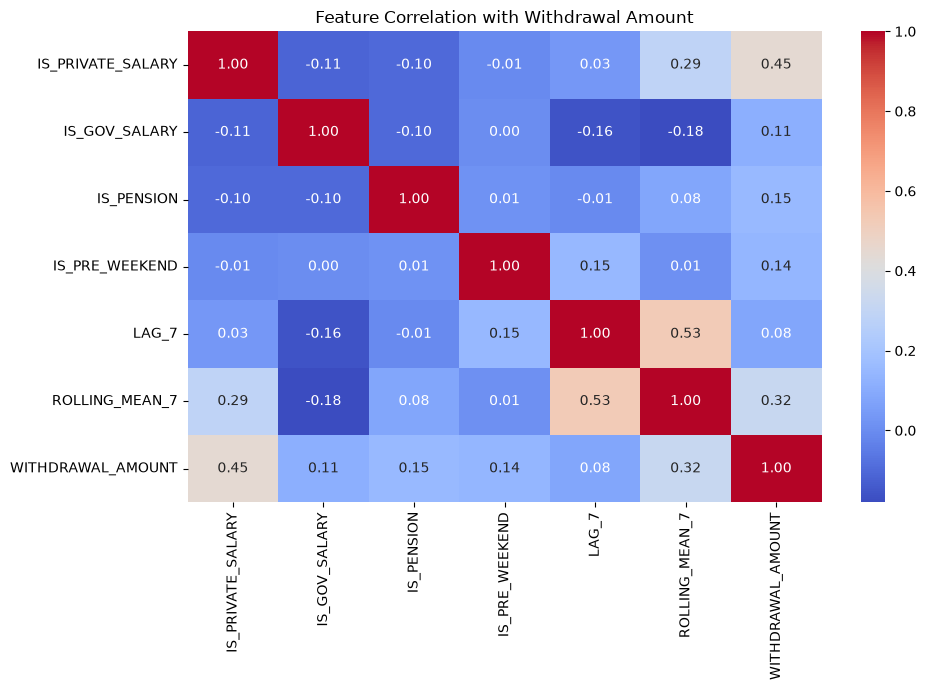

WITHDRAWAL_AMOUNT    1.000000
IS_PRIVATE_SALARY    0.445051
ROLLING_MEAN_7       0.321449
IS_PENSION           0.151633
IS_PRE_WEEKEND       0.142313
IS_GOV_SALARY        0.110394
LAG_7                0.079582
Name: WITHDRAWAL_AMOUNT, dtype: float64


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('merged.csv', low_memory=False)
df['TRAN_DATE'] = pd.to_datetime(df['TRAN_DATE'], format='%d-%b-%y')
df['DAY_OF_WEEK'] = df['DAY_OF_WEEK'].str.strip()

# Daily aggregation
daily = df.groupby('TRAN_DATE')['WITHDRAWAL_AMOUNT'].sum().reset_index()
daily = daily.sort_values('TRAN_DATE').reset_index(drop=True)

# Features
daily['DAY_OF_MONTH']      = daily['TRAN_DATE'].dt.day
daily['DAY_OF_WEEK_NAME']  = daily['TRAN_DATE'].dt.day_name()
daily['IS_PRIVATE_SALARY'] = daily['DAY_OF_MONTH'].between(1, 3).astype(int)
daily['IS_GOV_SALARY']     = daily['DAY_OF_MONTH'].between(23, 25).astype(int)
daily['IS_PENSION']        = daily['DAY_OF_MONTH'].between(29, 31).astype(int)
daily['IS_PRE_WEEKEND']    = (daily['DAY_OF_WEEK_NAME'] == 'Thursday').astype(int)
daily['LAG_7']             = daily['WITHDRAWAL_AMOUNT'].shift(7)
daily['ROLLING_MEAN_7']    = daily['WITHDRAWAL_AMOUNT'].shift(1).rolling(7).mean()

daily = daily.dropna().reset_index(drop=True)

# Correlation
features = [
    'IS_PRIVATE_SALARY', 'IS_GOV_SALARY', 'IS_PENSION',
    'IS_PRE_WEEKEND', 'LAG_7', 'ROLLING_MEAN_7', 'WITHDRAWAL_AMOUNT'
]

corr = daily[features].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Feature Correlation with Withdrawal Amount')
plt.tight_layout()
plt.show()

# Print correlation with target only
print(corr['WITHDRAWAL_AMOUNT'].sort_values(ascending=False))

In [4]:
for col in df.columns:
    print(col)

ATM_ID
BANK_ID
ATM_CODE
ATM_LOCATION
C1_DENOM
C1_CAPACITY
C2_DENOM
C2_CAPACITY
C3_DENOM
C3_CAPACITY
C4_DENOM
C4_CAPACITY
DEPOSIT_SUPPORT
FOREX_SUPPORT
COMPANY_ID
CITY_CODE
ATM_LINE
MIN_TARGET_AMOUNT
MAX_TARGET_AMOUNT
ATM_VENDOR
ATM_ADDRESS
ATM_TYPE
ATM_MODEL
CASSETTE_MODEL
DEPOSIT_DEVICE
SERIAL_NO
ATM_IP
FOREX_ATM_ID
BANK_RESPONSIBILITY
AUTO_ADJ_FLAG
REFILL_PERCENT_MARGIN
RETURN_PERCENT_MARGIN
MAX_REFILL_DURATION
MORNING
EVENING
WEEKEND
HOLIDAY
ACTIVE_FLAG
REFERENCE_ATM
ATM_USERNAME
ATM_PASSWORD
CONNECTIVITY_STATUS
AGENT_STATUS
ATM_PORT
COM_TYPE
INSTALLATION_DATE
EVENING_REFILL_SAFETY_MARGIN
EXCEPTION_MIN_THRESHOLD
EXCEPTION_MAX_THRESHOLD
PAYROLL_AMOUNT_THRESHOLD
PAYROLL_PROBABILITY_THRESHOLD
PAYROL_EXCEPTION_MAX_THRESHOLD
COUPLE_GROUP
REMOVE_DATE
CURRENT_ONLINEBAL
LAST_ONLINEBAL_DATE
ONLINEBAL_C1
ONLINEBAL_C2
ONLINEBAL_C3
ONLINEBAL_C4
REMOTE_HOST
REMOTE_PORT
TEMPLATE_ID
REG_PATH
FLM_SP_ID
SLM_SP_ID
CIT_ZONE_ID
FLM_ZONE_ID
SLM_ZONE_ID
CIT_ZONE_NAME
FLM_ZONE_NAME
SLM_ZONE_NAME
TEMP_COMP

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load CSV
df = pd.read_csv("merged.csv")

# Convert date
df["TRAN_DATE"] = pd.to_datetime(df["TRAN_DATE"], errors="coerce")

# Convert withdrawal amount to numeric
df["WITHDRAWAL_AMOUNT"] = pd.to_numeric(
    df["WITHDRAWAL_AMOUNT"], errors="coerce"
)

# Remove invalid values
df = df.dropna(subset=["TRAN_DATE", "WITHDRAWAL_AMOUNT"])

# Sort by date
df = df.sort_values("TRAN_DATE")

# Plot
plt.figure(figsize=(15, 6))

plt.plot(
    df["TRAN_DATE"],
    df["WITHDRAWAL_AMOUNT"],
    linewidth=1
)

plt.xlabel("Transaction Date")
plt.ylabel("Withdrawal Amount")
plt.title("Withdrawal Amount Timeline")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

C:\Users\dell\AppData\Local\Temp\ipykernel_20468\1083829411.py:5: DtypeWarning: Columns (25,38,39,40,53,60) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("merged.csv")


0    175000
1    405500
2    363400
3    116500
4    164100
5    119000
6    151850
7    155450
8    190050
9    429700
Name: WITHDRAWAL_AMOUNT, dtype: int64
int64


C:\Users\dell\AppData\Local\Temp\ipykernel_20468\1083829411.py:26: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["TRAN_DATE"] = pd.to_datetime(



After conversion:
   TRAN_DATE  WITHDRAWAL_AMOUNT
0 2024-12-04             175000
1 2024-12-30             405500
2 2024-12-01             363400
3 2024-11-30             116500
4 2024-12-22             164100
5 2024-12-18             119000
6 2024-12-10             151850
7 2024-12-14             155450
8 2024-12-09             190050
9 2024-11-28             429700

Missing values:
TRAN_DATE            0
WITHDRAWAL_AMOUNT    0
dtype: int64


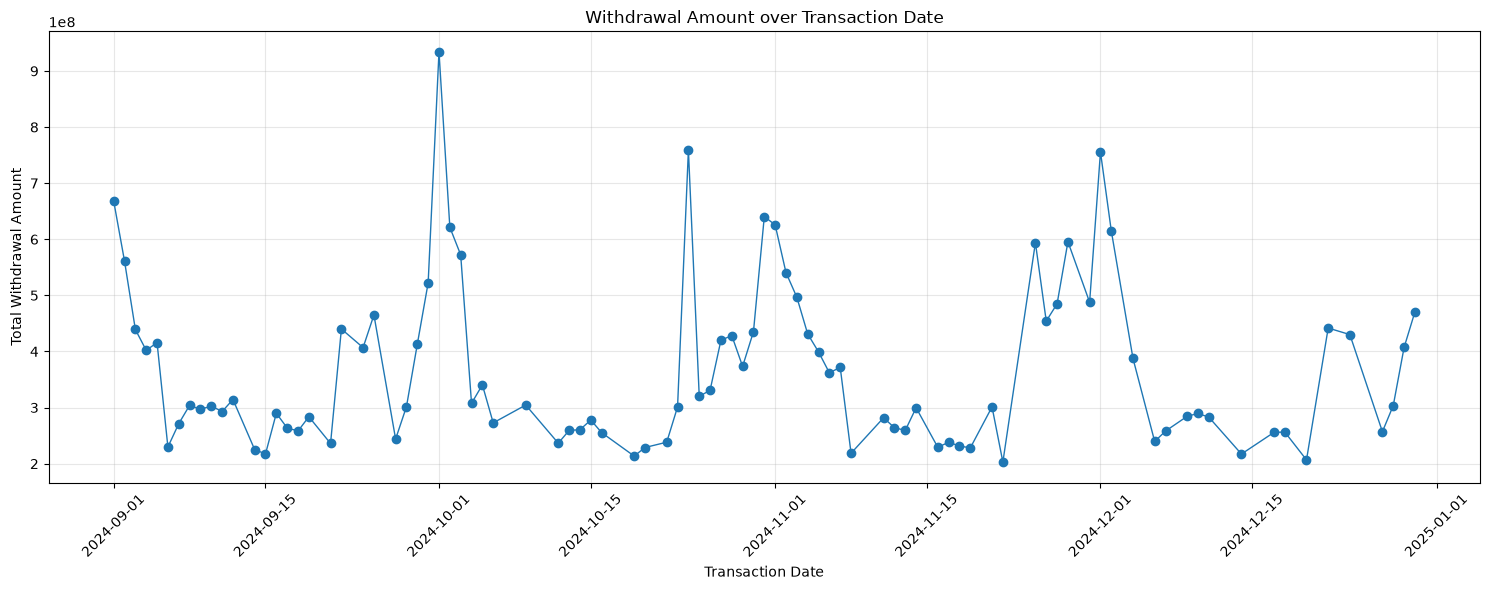

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Read CSV
df = pd.read_csv("merged.csv")

# Check original values
print(df["WITHDRAWAL_AMOUNT"].head(10))
print(df["WITHDRAWAL_AMOUNT"].dtype)

# Clean WITHDRAWAL_AMOUNT
df["WITHDRAWAL_AMOUNT"] = (
    df["WITHDRAWAL_AMOUNT"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace(" ", "", regex=False)
)

# Convert to numeric
df["WITHDRAWAL_AMOUNT"] = pd.to_numeric(
    df["WITHDRAWAL_AMOUNT"],
    errors="coerce"
)

# Convert date
df["TRAN_DATE"] = pd.to_datetime(
    df["TRAN_DATE"],
    errors="coerce"
)

# Check result
print("\nAfter conversion:")
print(df[["TRAN_DATE", "WITHDRAWAL_AMOUNT"]].head(10))
print("\nMissing values:")
print(df[["TRAN_DATE", "WITHDRAWAL_AMOUNT"]].isna().sum())

# Remove invalid rows
df = df.dropna(
    subset=["TRAN_DATE", "WITHDRAWAL_AMOUNT"]
)

# Sort by date
df = df.sort_values("TRAN_DATE")

# Aggregate by date
daily = (
    df.groupby(df["TRAN_DATE"].dt.date)["WITHDRAWAL_AMOUNT"]
      .sum()
      .reset_index()
)

daily["TRAN_DATE"] = pd.to_datetime(daily["TRAN_DATE"])

# Plot
plt.figure(figsize=(15, 6))

plt.plot(
    daily["TRAN_DATE"],
    daily["WITHDRAWAL_AMOUNT"],
    marker="o",
    linewidth=1
)

plt.xlabel("Transaction Date")
plt.ylabel("Total Withdrawal Amount")
plt.title("Withdrawal Amount over Transaction Date")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import plotly.express as px

# Load data
df = pd.read_csv("merged.csv")

# Convert columns
df["TRAN_DATE"] = pd.to_datetime(df["TRAN_DATE"], errors="coerce")

df["WITHDRAWAL_AMOUNT"] = (
    df["WITHDRAWAL_AMOUNT"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace(" ", "", regex=False)
)

df["WITHDRAWAL_AMOUNT"] = pd.to_numeric(
    df["WITHDRAWAL_AMOUNT"],
    errors="coerce"
)

# Remove missing values
df = df.dropna(
    subset=["TRAN_DATE", "WITHDRAWAL_AMOUNT"]
)

# Sort by date
df = df.sort_values("TRAN_DATE")

# Aggregate by day
daily = (
    df.groupby(df["TRAN_DATE"].dt.date)["WITHDRAWAL_AMOUNT"]
      .sum()
      .reset_index()
)

daily["TRAN_DATE"] = pd.to_datetime(daily["TRAN_DATE"])

# Interactive plot
fig = px.line(
    daily,
    x="TRAN_DATE",
    y="WITHDRAWAL_AMOUNT",
    markers=True,
    title="Withdrawal Amount over Transaction Date"
)

fig.update_layout(
    xaxis_title="Transaction Date",
    yaxis_title="Total Withdrawal Amount",
    hovermode="x unified"
)

fig.show()

C:\Users\dell\AppData\Local\Temp\ipykernel_20468\618372251.py:5: DtypeWarning: Columns (25,38,39,40,53,60) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("merged.csv")
C:\Users\dell\AppData\Local\Temp\ipykernel_20468\618372251.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["TRAN_DATE"] = pd.to_datetime(df["TRAN_DATE"], errors="coerce")


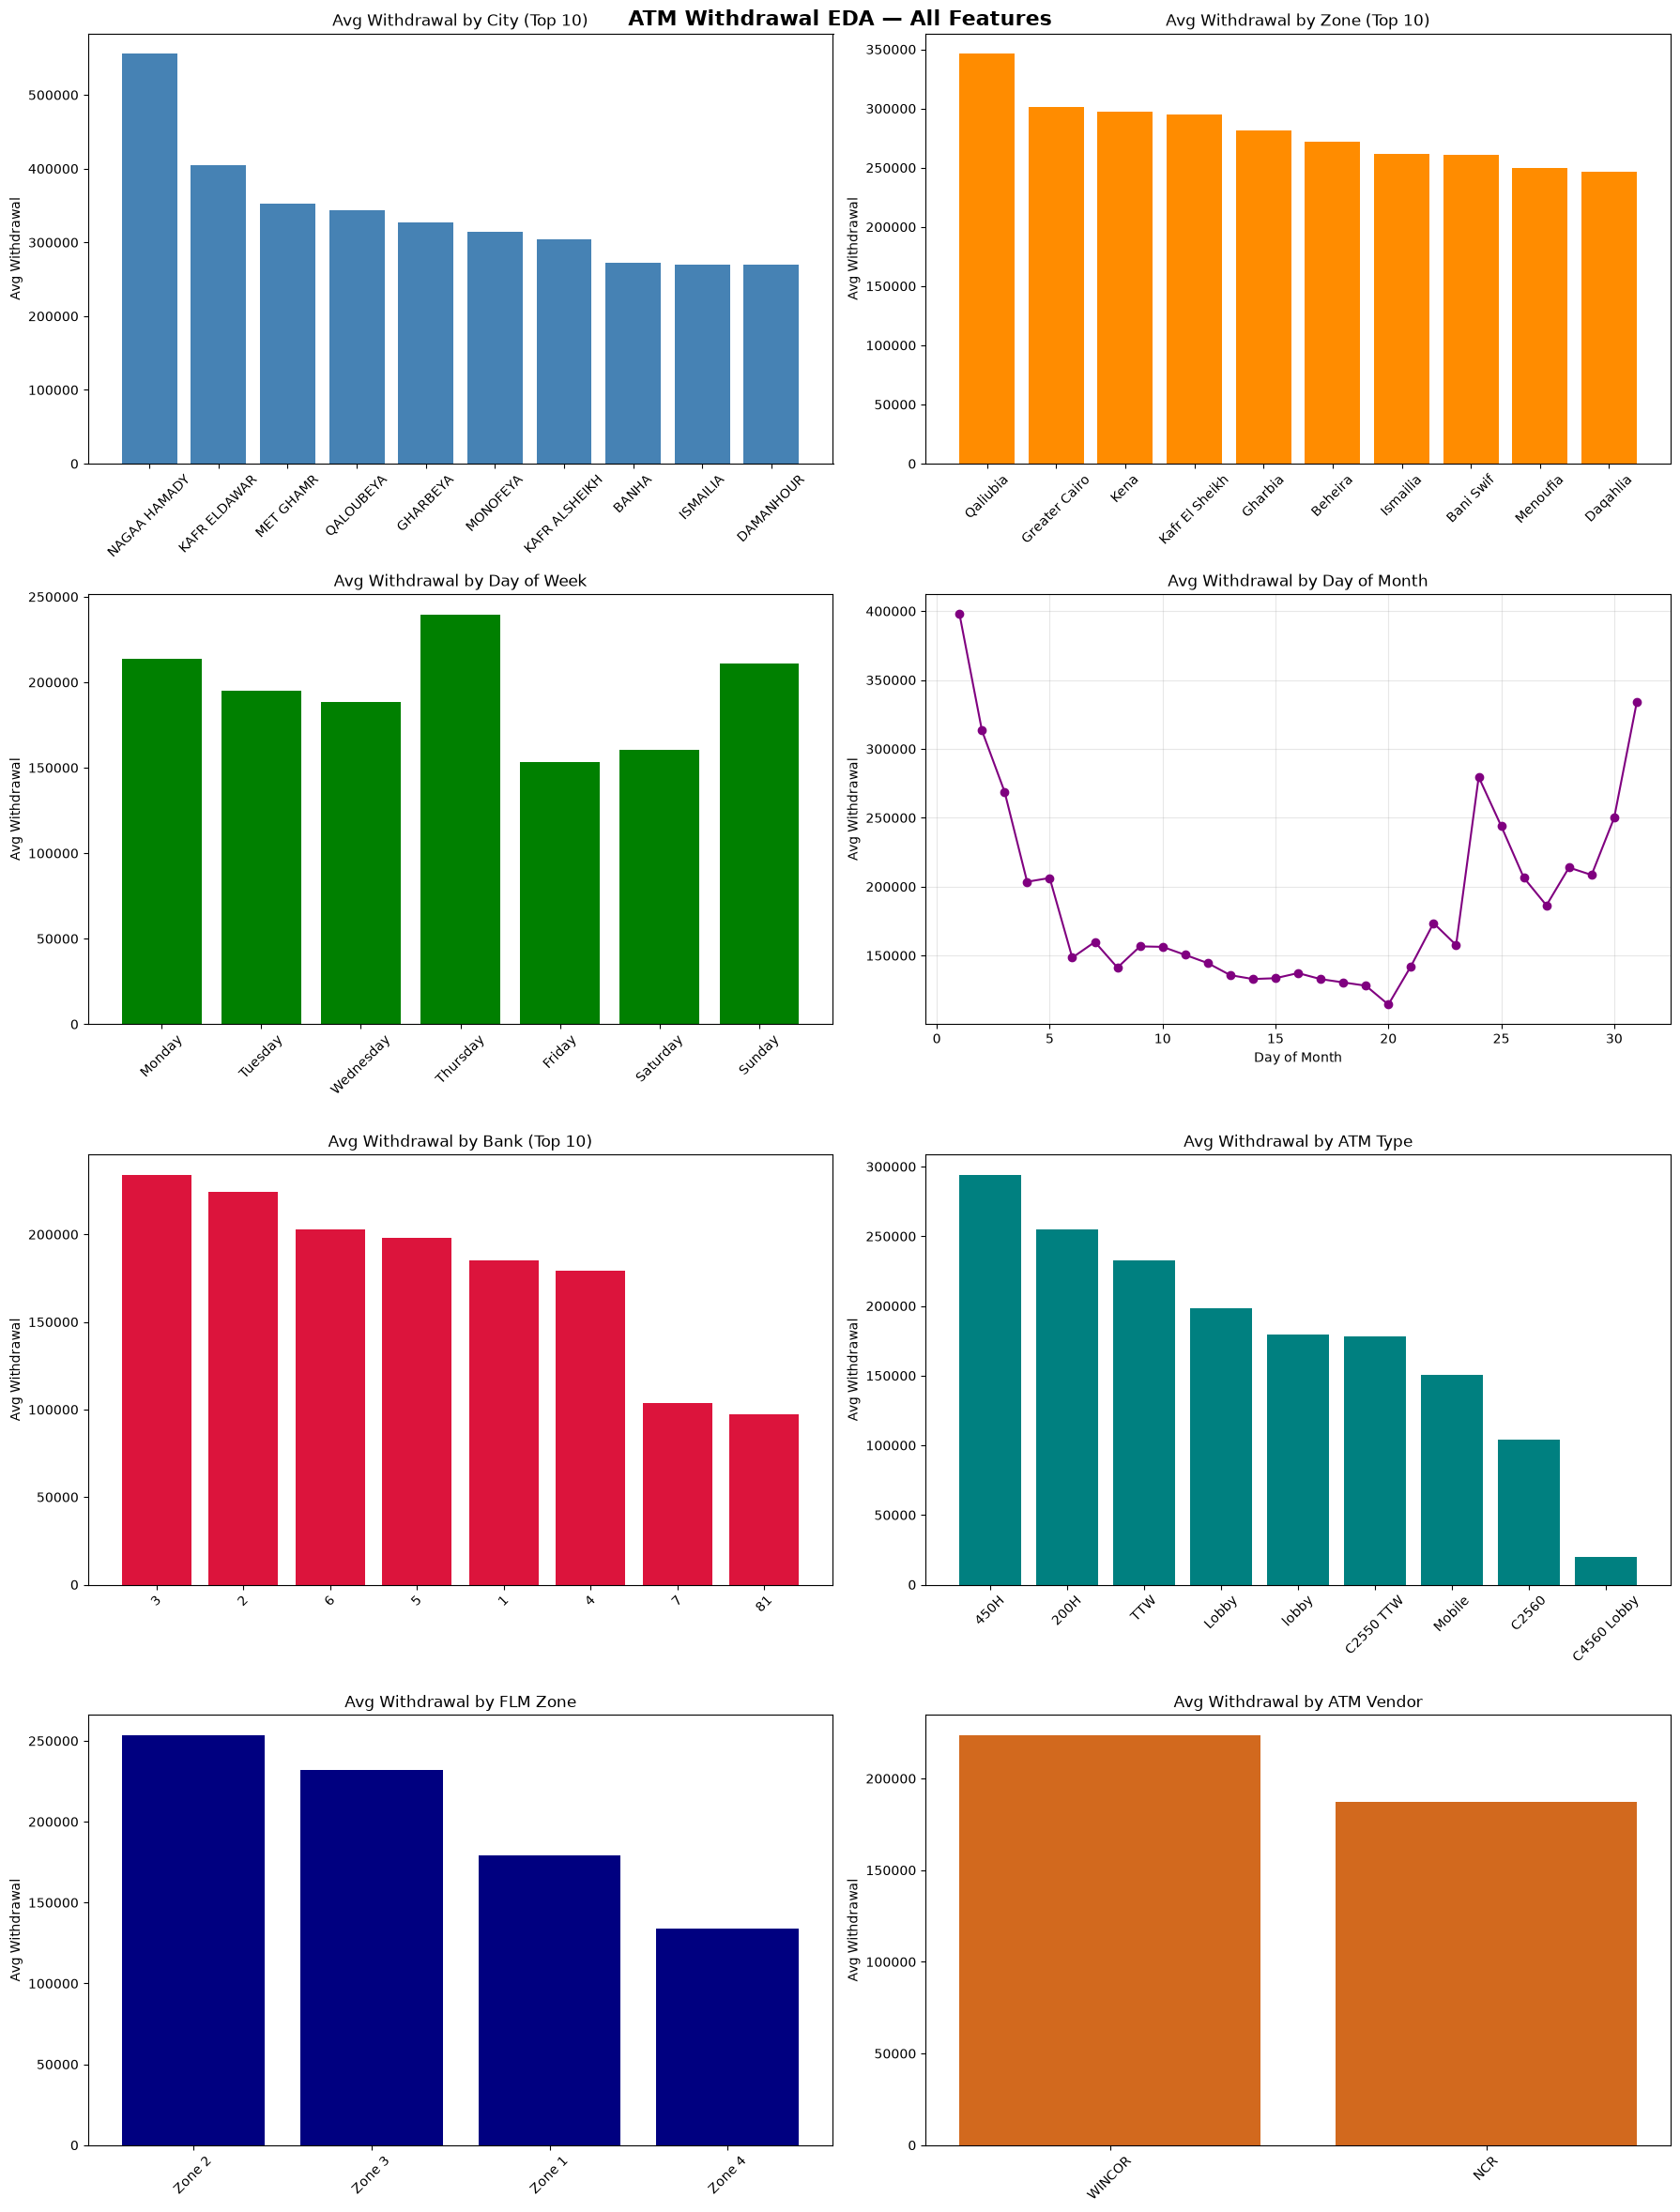

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# ==================== Load Data ====================
df = pd.read_csv('merged.csv', low_memory=False)
df['TRAN_DATE'] = pd.to_datetime(df['TRAN_DATE'], format='%d-%b-%y')
df['DAY_OF_WEEK'] = df['DAY_OF_WEEK'].str.strip()
df['DAY_OF_MONTH'] = df['TRAN_DATE'].dt.day
df['DAY_OF_WEEK_NAME'] = df['TRAN_DATE'].dt.day_name()

fig, axes = plt.subplots(4, 2, figsize=(18, 24))
fig.suptitle('ATM Withdrawal EDA — All Features', fontsize=16, fontweight='bold')

# ==================== 1. City ====================
city = df.groupby('CITY_CODE')['WITHDRAWAL_AMOUNT'].mean().sort_values(ascending=False).head(10)
axes[0,0].bar(city.index, city.values, color='steelblue')
axes[0,0].set_title('Avg Withdrawal by City (Top 10)')
axes[0,0].tick_params(axis='x', rotation=45)
axes[0,0].set_ylabel('Avg Withdrawal')

# ==================== 2. Zone ====================
zone = df.groupby('CIT_ZONE_NAME')['WITHDRAWAL_AMOUNT'].mean().sort_values(ascending=False).head(10)
axes[0,1].bar(zone.index, zone.values, color='darkorange')
axes[0,1].set_title('Avg Withdrawal by Zone (Top 10)')
axes[0,1].tick_params(axis='x', rotation=45)
axes[0,1].set_ylabel('Avg Withdrawal')

# ==================== 3. Day of Week ====================
dow_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
dow = df.groupby('DAY_OF_WEEK_NAME')['WITHDRAWAL_AMOUNT'].mean().reindex(dow_order)
axes[1,0].bar(dow.index, dow.values, color='green')
axes[1,0].set_title('Avg Withdrawal by Day of Week')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].set_ylabel('Avg Withdrawal')

# ==================== 4. Day of Month ====================
dom = df.groupby('DAY_OF_MONTH')['WITHDRAWAL_AMOUNT'].mean()
axes[1,1].plot(dom.index, dom.values, marker='o', color='purple')
axes[1,1].set_title('Avg Withdrawal by Day of Month')
axes[1,1].set_xlabel('Day of Month')
axes[1,1].set_ylabel('Avg Withdrawal')
axes[1,1].grid(True, alpha=0.3)

# ==================== 5. Bank ====================
bank = df.groupby('BANK_ID')['WITHDRAWAL_AMOUNT'].mean().sort_values(ascending=False).head(10)
axes[2,0].bar(bank.index.astype(str), bank.values, color='crimson')
axes[2,0].set_title('Avg Withdrawal by Bank (Top 10)')
axes[2,0].tick_params(axis='x', rotation=45)
axes[2,0].set_ylabel('Avg Withdrawal')

# ==================== 6. ATM Type ====================
atm_type = df.groupby('ATM_TYPE')['WITHDRAWAL_AMOUNT'].mean().sort_values(ascending=False)
axes[2,1].bar(atm_type.index, atm_type.values, color='teal')
axes[2,1].set_title('Avg Withdrawal by ATM Type')
axes[2,1].tick_params(axis='x', rotation=45)
axes[2,1].set_ylabel('Avg Withdrawal')

# ==================== 7. FLM Zone ====================
flm = df.groupby('FLM_ZONE_NAME')['WITHDRAWAL_AMOUNT'].mean().sort_values(ascending=False)
axes[3,0].bar(flm.index, flm.values, color='navy')
axes[3,0].set_title('Avg Withdrawal by FLM Zone')
axes[3,0].tick_params(axis='x', rotation=45)
axes[3,0].set_ylabel('Avg Withdrawal')

# ==================== 8. ATM Vendor ====================
vendor = df.groupby('ATM_VENDOR')['WITHDRAWAL_AMOUNT'].mean().sort_values(ascending=False).head(10)
axes[3,1].bar(vendor.index, vendor.values, color='chocolate')
axes[3,1].set_title('Avg Withdrawal by ATM Vendor')
axes[3,1].tick_params(axis='x', rotation=45)
axes[3,1].set_ylabel('Avg Withdrawal')

plt.tight_layout()
plt.savefig('full_eda.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import pandas as pd
from scipy import stats

# ==================== Load Data ====================
df = pd.read_csv('merged.csv', low_memory=False)
df['TRAN_DATE'] = pd.to_datetime(df['TRAN_DATE'], format='%d-%b-%y')
df['DAY_OF_WEEK'] = df['DAY_OF_WEEK'].str.strip()
df['DAY_OF_WEEK_NAME'] = df['TRAN_DATE'].dt.day_name()

# ==================== Categorical Features ====================
categorical_features = [
    'CITY_CODE',
    'CIT_ZONE_NAME',
    'FLM_ZONE_NAME',
    'SLM_ZONE_NAME',
    'BANK_ID',
    'ATM_TYPE',
    'ATM_VENDOR',
    'DAY_OF_WEEK_NAME',
    'DEPOSIT_SUPPORT',
    'FOREX_SUPPORT',
    'MORNING',
    'EVENING',
    'WEEKEND',
    'HOLIDAY',
]

# ==================== ANOVA Test ====================
results = []

for feature in categorical_features:
    try:
        groups = [
            group['WITHDRAWAL_AMOUNT'].values
            for _, group in df.groupby(feature)
            if len(group) > 1
        ]
        if len(groups) < 2:
            continue

        f_stat, p_value = stats.f_oneway(*groups)

        results.append({
            'Feature'  : feature,
            'F-Stat'   : round(f_stat, 2),
            'P-Value'  : round(p_value, 6),
            'Significant': 'YES ✅' if p_value < 0.05 else 'NO ❌'
        })

    except Exception as e:
        print(f'Error in {feature}: {e}')

# ==================== Results ====================
results_df = pd.DataFrame(results).sort_values('P-Value')
print(results_df.to_string(index=False))

         Feature  F-Stat  P-Value Significant
       CITY_CODE  274.91 0.000000       YES ✅
   CIT_ZONE_NAME  439.14 0.000000       YES ✅
   FLM_ZONE_NAME 1937.39 0.000000       YES ✅
   SLM_ZONE_NAME  470.91 0.000000       YES ✅
         BANK_ID 1094.12 0.000000       YES ✅
        ATM_TYPE  135.60 0.000000       YES ✅
      ATM_VENDOR 1190.65 0.000000       YES ✅
DAY_OF_WEEK_NAME  516.20 0.000000       YES ✅
 DEPOSIT_SUPPORT 3207.47 0.000000       YES ✅
   FOREX_SUPPORT  243.70 0.000000       YES ✅
         EVENING 3065.57 0.000000       YES ✅
         WEEKEND   44.04 0.000000       YES ✅
         HOLIDAY   44.56 0.000000       YES ✅
         MORNING   11.07 0.000877       YES ✅


Dataset shape: (171760, 93)
Rows after target cleaning: 171760

================ COLUMN TYPES ================

Categorical columns:
['ATM_LOCATION', 'CITY_CODE', 'ATM_VENDOR', 'ATM_ADDRESS', 'ATM_TYPE', 'ATM_MODEL', 'CASSETTE_MODEL', 'DEPOSIT_DEVICE', 'AGENT_STATUS', 'CIT_ZONE_NAME', 'FLM_ZONE_NAME', 'SLM_ZONE_NAME', 'DAY_OF_WEEK', 'DAY_OF_WEEK_NAME']

Numerical columns:
['ATM_ID', 'BANK_ID', 'C1_DENOM', 'C1_CAPACITY', 'C2_DENOM', 'C2_CAPACITY', 'C3_DENOM', 'C3_CAPACITY', 'C4_DENOM', 'C4_CAPACITY', 'DEPOSIT_SUPPORT', 'FOREX_SUPPORT', 'COMPANY_ID', 'ATM_LINE', 'MIN_TARGET_AMOUNT', 'MAX_TARGET_AMOUNT', 'BANK_RESPONSIBILITY', 'REFILL_PERCENT_MARGIN', 'RETURN_PERCENT_MARGIN', 'MAX_REFILL_DURATION', 'MORNING', 'EVENING', 'WEEKEND', 'HOLIDAY', 'EVENING_REFILL_SAFETY_MARGIN', 'EXCEPTION_MIN_THRESHOLD', 'EXCEPTION_MAX_THRESHOLD', 'PAYROLL_AMOUNT_THRESHOLD', 'PAYROLL_PROBABILITY_THRESHOLD', 'PAYROL_EXCEPTION_MAX_THRESHOLD', 'CURRENT_ONLINEBAL', 'ONLINEBAL_C1', 'ONLINEBAL_C2', 'ONLINEBAL_C3', '

,Feature,F_Statistic,P_Value,N_Groups,N_Observations,Adjusted_P_Value,Significant
2,CASSETTE_MODEL,157.696318,0.0,25,18437,0.0,YES
6,FLM_ZONE_NAME,1937.385090,0.0,4,171760,0.0,YES
5,CIT_ZONE_NAME,439.140935,0.0,27,171614,0.0,YES
4,AGENT_STATUS,4023.095222,0.0,2,88545,0.0,YES
7,SLM_ZONE_NAME,470.908528,0.0,15,171760,0.0,YES
8,DAY_OF_WEEK,516.201541,0.0,7,171760,0.0,YES
9,DAY_OF_WEEK_NAME,516.201541,0.0,7,171760,0.0,YES
3,DEPOSIT_DEVICE,275.936009,0.0,6,111122,0.0,YES
0,ATM_VENDOR,1190.646117,0.0,2,162652,0.0,YES
1,ATM_TYPE,135.596999,0.0,9,135164,0.0,YES




NUMERICAL FEATURES - CORRELATION


,Feature,Pearson,Pearson_P_Value,Spearman,Spearman_P_Value,N_Observations,Pearson_Adjusted_P,Spearman_Adjusted_P,Pearson_Significant,Spearman_Significant,Absolute_Pearson,Absolute_Spearman
51,AMOUNT,0.979451,0.000000,0.977386,0.000000,171760,0.000000,0.000000,True,True,0.979451,0.977386
36,TEMPLATE_ID,-0.308395,0.000000,-0.352804,0.000000,1054,0.000000,0.000000,True,True,0.308395,0.352804
0,ATM_ID,-0.200843,0.000000,-0.220985,0.000000,171760,0.000000,0.000000,True,True,0.200843,0.220985
57,IS_PRIVATE_SALARY,0.258373,0.000000,0.203889,0.000000,171760,0.000000,0.000000,True,True,0.258373,0.203889
47,ONLINE_DEP_D100,0.046866,0.000000,0.194020,0.000000,142932,0.000000,0.000000,True,True,0.046866,0.194020
48,ONLINE_DEP_D200,0.041773,0.000000,0.193177,0.000000,142932,0.000000,0.000000,True,True,0.041773,0.193177
46,ONLINE_DEP_D50,0.052195,0.000000,0.183734,0.000000,142932,0.000000,0.000000,True,True,0.052195,0.183734
37,FLM_SP_ID,-0.122679,0.000000,-0.169299,0.000000,171760,0.000000,0.000000,True,True,0.122679,0.169299
10,DEPOSIT_SUPPORT,0.135396,0.000000,0.163073,0.000000,171760,0.000000,0.000000,True,True,0.135396,0.163073
35,REMOTE_PORT,-0.269595,0.000000,-0.160053,0.002870,345,0.000000,0.003068,True,True,0.269595,0.160053




SUMMARY
Total rows: 171,760
Total columns: 101
Categorical features analyzed: 10
Numerical features analyzed: 62
Significant categorical features after correction: 10
Significant numerical features (Pearson): 57
Significant numerical features (Spearman): 60


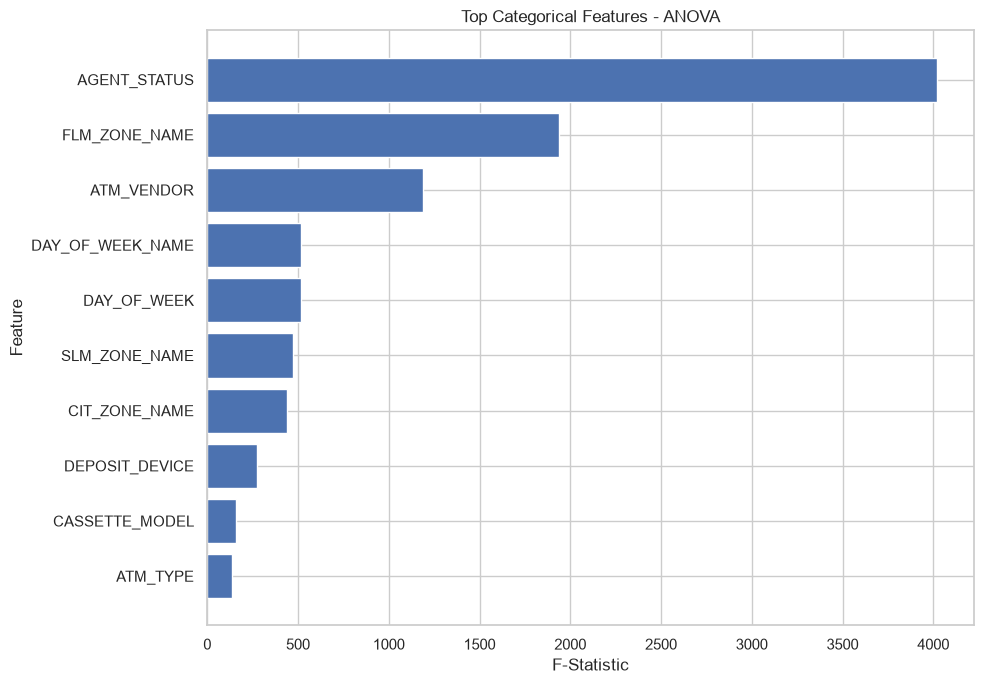

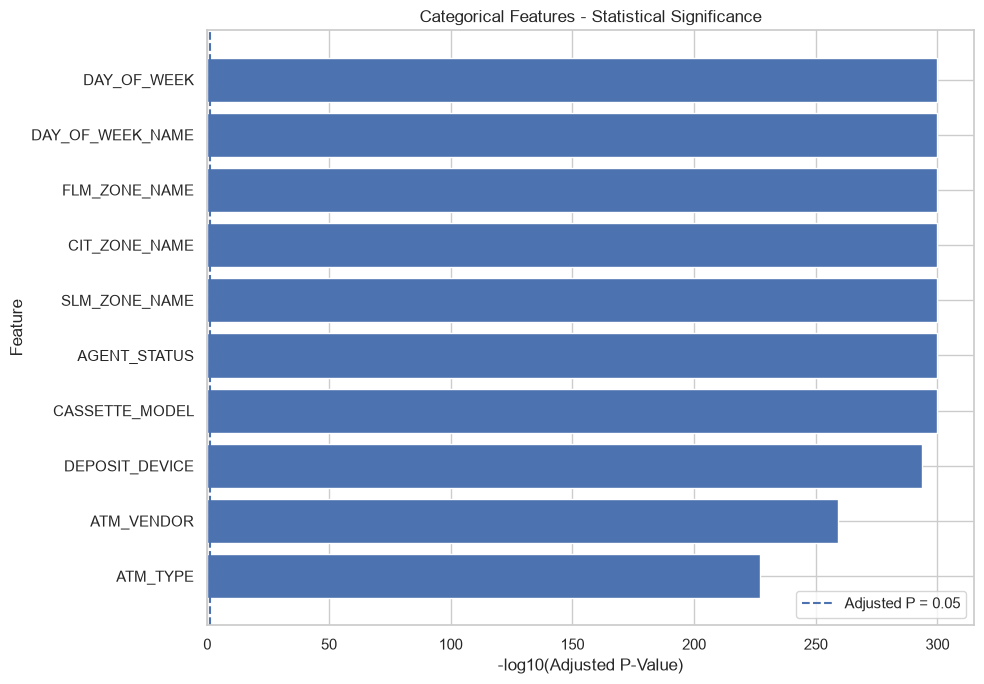

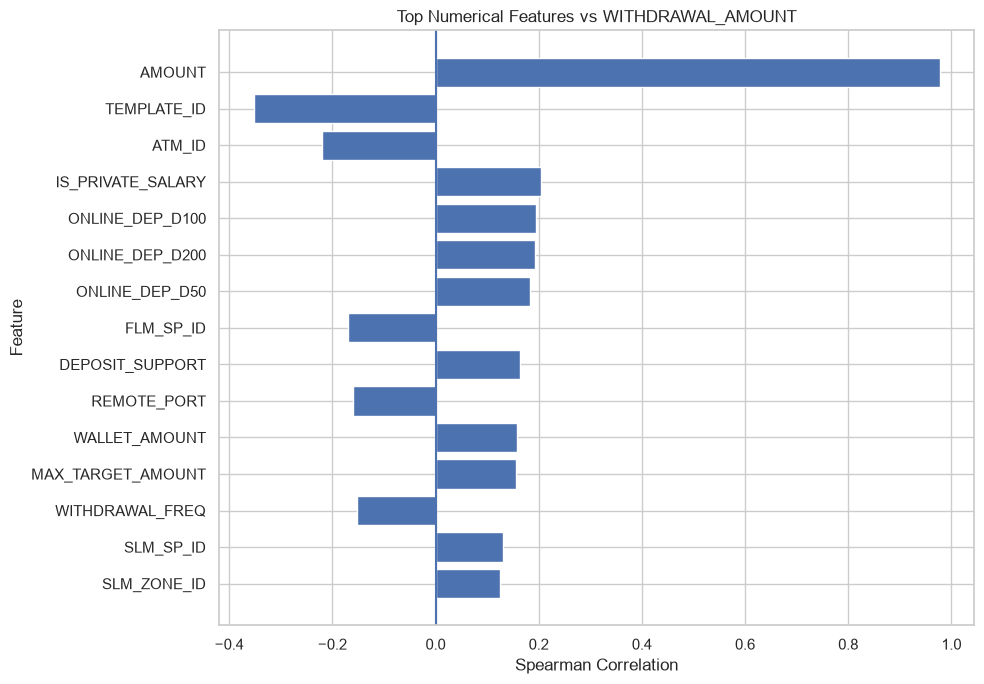

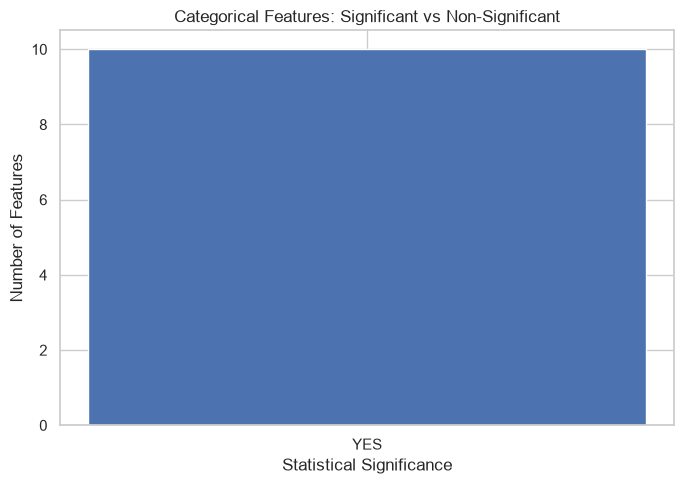

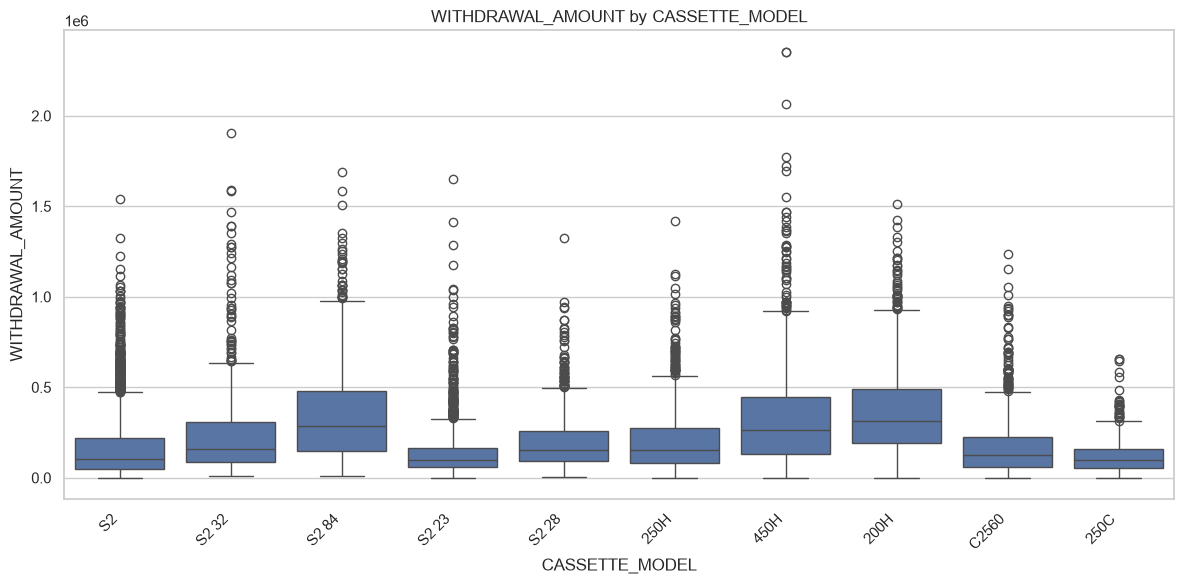

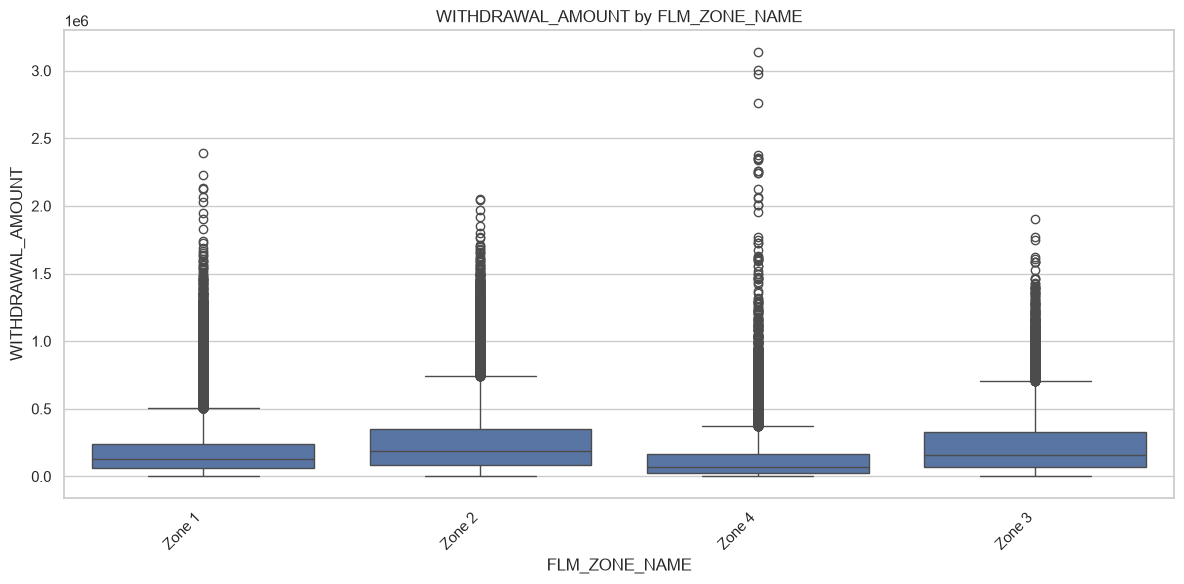

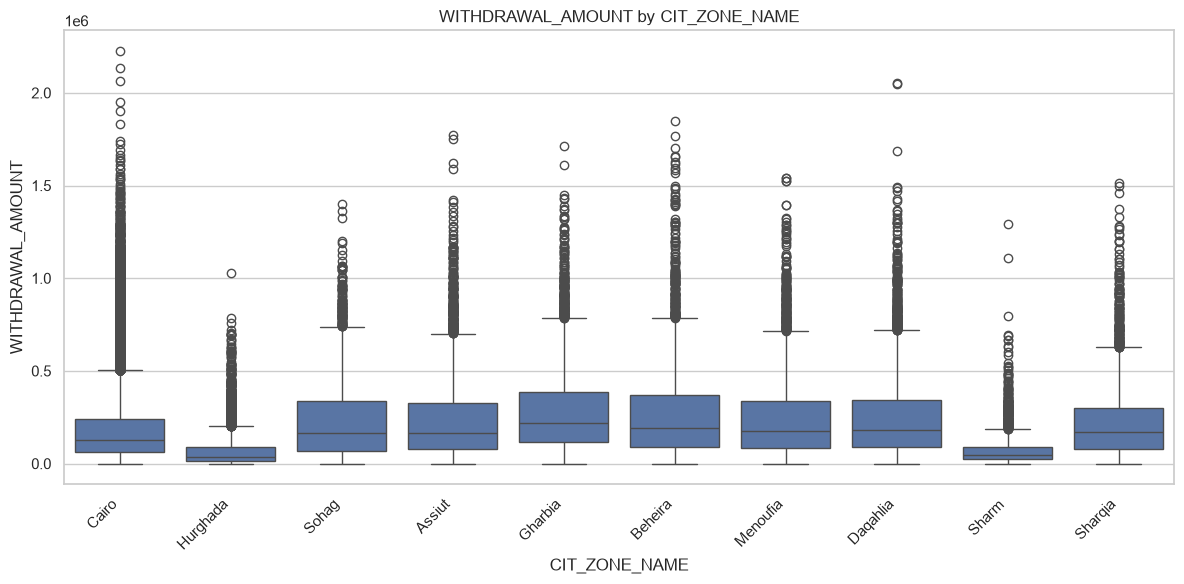

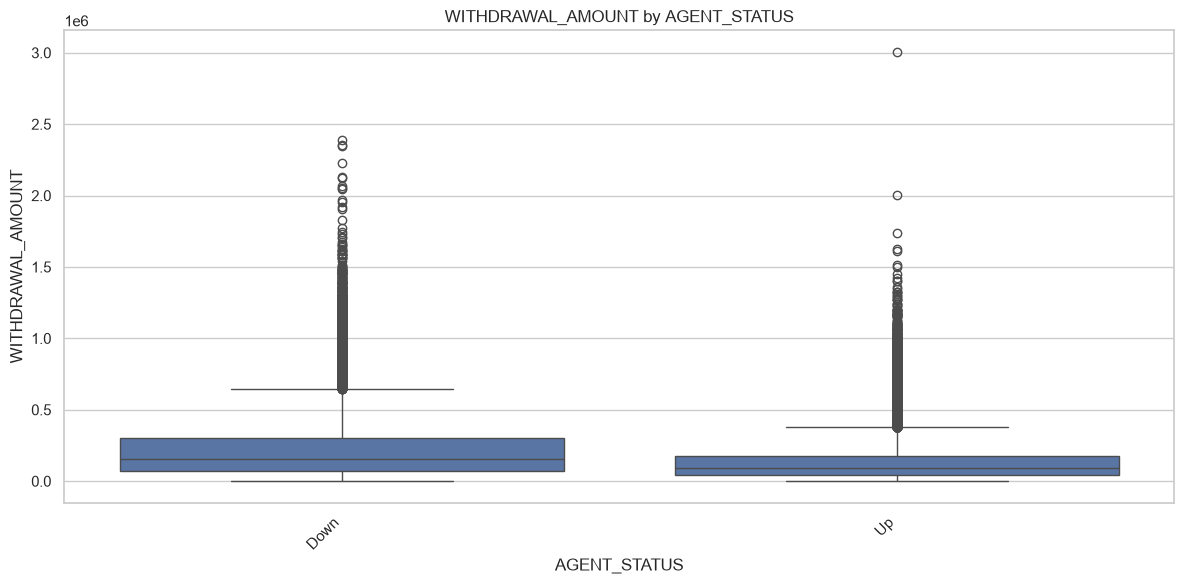

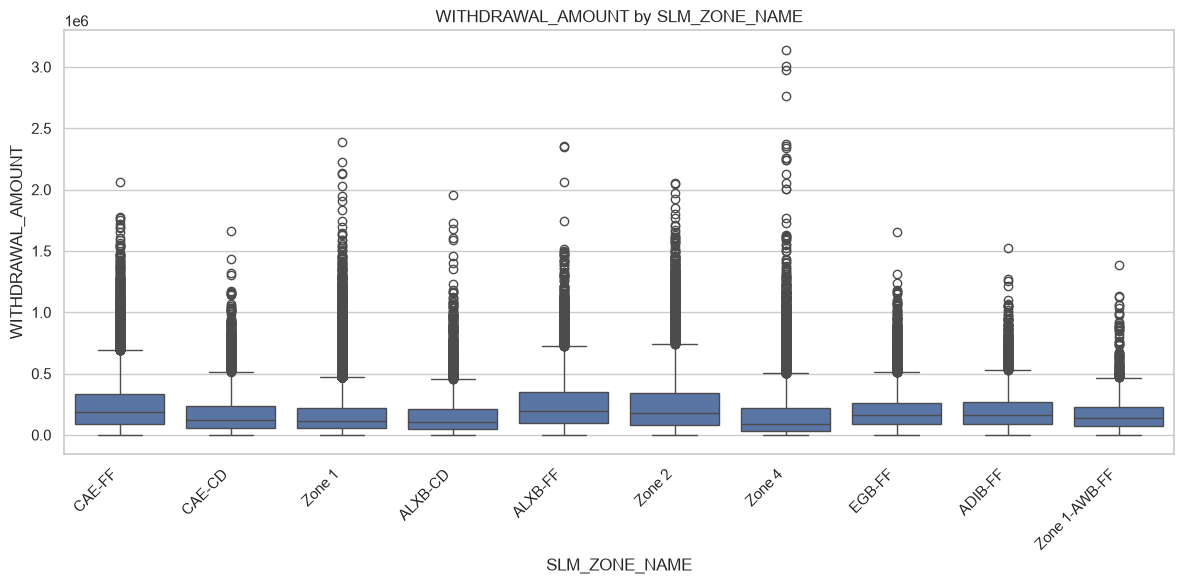

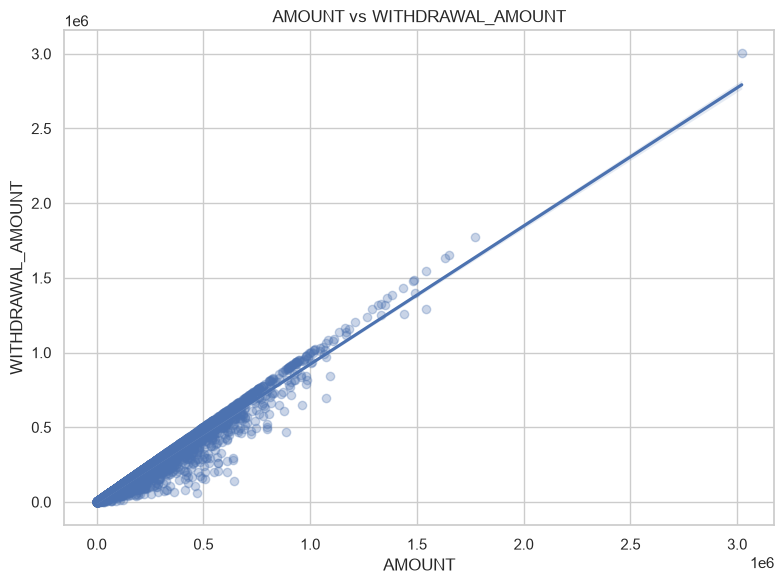

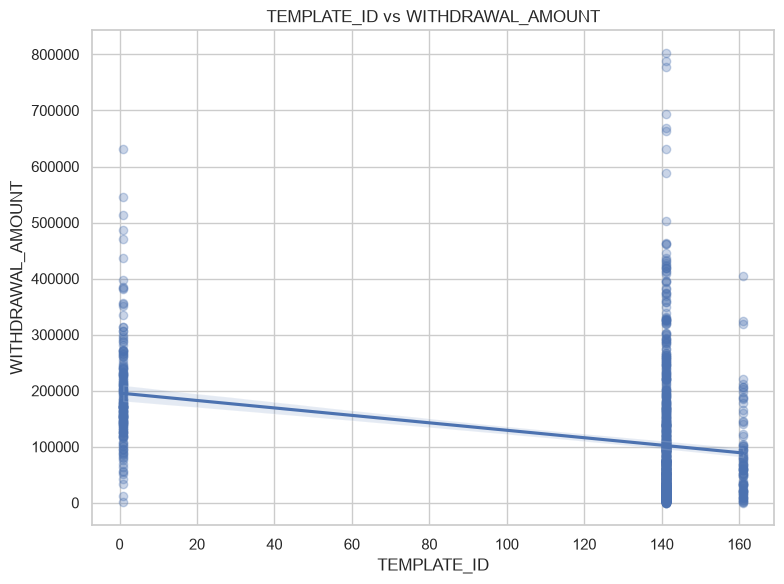

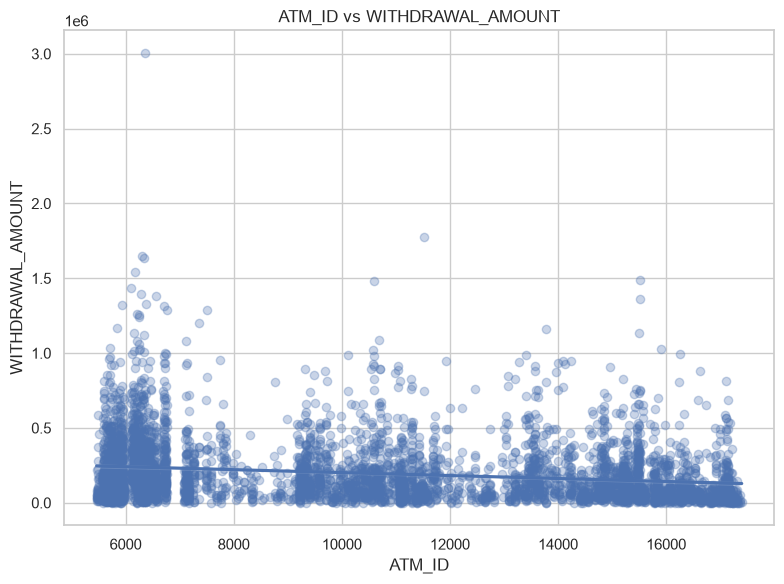

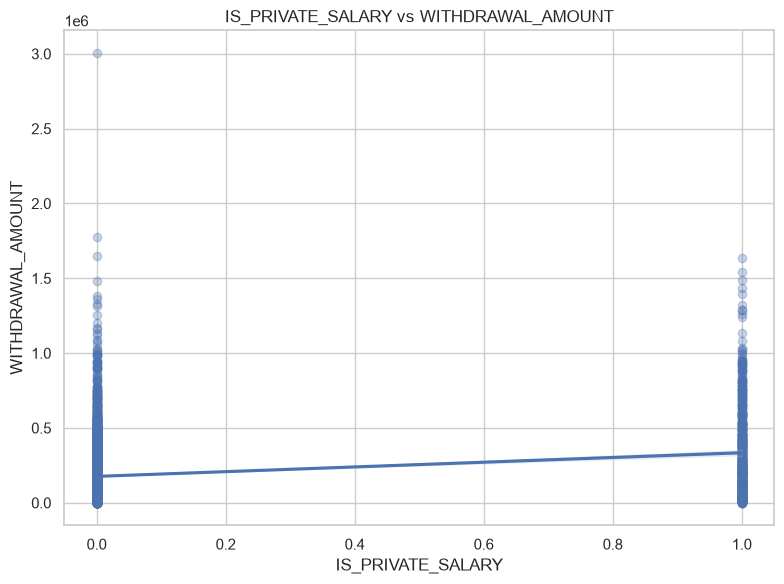

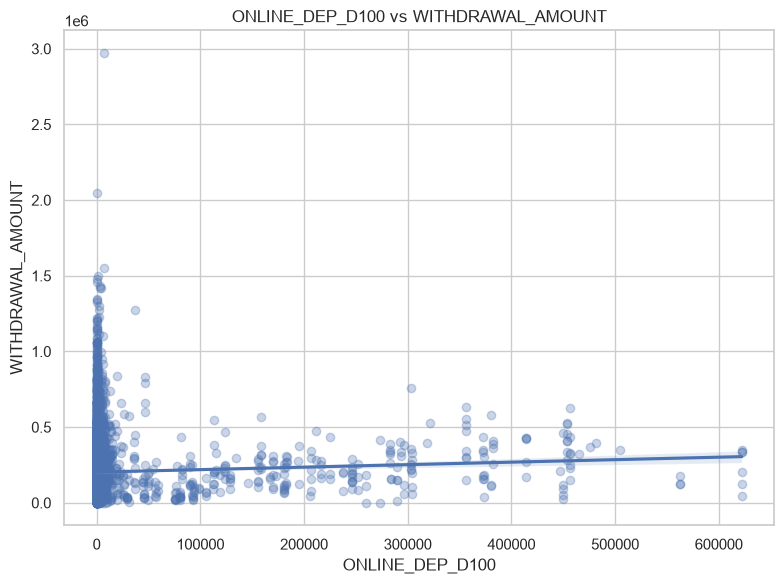



TOP CATEGORICAL FEATURES
         Feature  F_Statistic  Adjusted_P_Value Significant
  CASSETTE_MODEL   157.696318      0.000000e+00         YES
   FLM_ZONE_NAME  1937.385090      0.000000e+00         YES
   CIT_ZONE_NAME   439.140935      0.000000e+00         YES
    AGENT_STATUS  4023.095222      0.000000e+00         YES
   SLM_ZONE_NAME   470.908528      0.000000e+00         YES
     DAY_OF_WEEK   516.201541      0.000000e+00         YES
DAY_OF_WEEK_NAME   516.201541      0.000000e+00         YES
  DEPOSIT_DEVICE   275.936009     2.987520e-294         YES
      ATM_VENDOR  1190.646117     6.415462e-260         YES
        ATM_TYPE   135.596999     6.323701e-228         YES


TOP NUMERICAL FEATURES
          Feature   Pearson  Spearman  Spearman_Adjusted_P  Spearman_Significant
           AMOUNT  0.979451  0.977386         0.000000e+00                  True
      TEMPLATE_ID -0.308395 -0.352804         4.302174e-32                  True
           ATM_ID -0.200843 -0.220985        

In [ ]:
# ============================================================
# ATM WITHDRAWAL - AUTOMATIC FEATURE ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.multitest import multipletests


# ============================================================
# 1. LOAD DATA
# ============================================================

df = pd.read_csv("merged.csv", low_memory=False)

print("Dataset shape:", df.shape)

# Target
TARGET = "WITHDRAWAL_AMOUNT"

if TARGET not in df.columns:
    raise ValueError(f"{TARGET} is not found in the dataset.")


# ============================================================
# 2. DATE PROCESSING
# ============================================================

if "TRAN_DATE" in df.columns:

    df["TRAN_DATE"] = pd.to_datetime(
        df["TRAN_DATE"],
        format="%d-%b-%y",
        errors="coerce"
    )

    # Time features
    df["DAY_OF_MONTH"] = df["TRAN_DATE"].dt.day

    df["DAY_OF_WEEK_NAME"] = (
        df["TRAN_DATE"]
        .dt.day_name()
    )

    df["MONTH"] = df["TRAN_DATE"].dt.month

    df["WEEK_OF_YEAR"] = (
        df["TRAN_DATE"]
        .dt.isocalendar()
        .week
        .astype("Int64")
    )

    # Salary / pension periods
    df["IS_PRIVATE_SALARY"] = (
        df["DAY_OF_MONTH"].between(1, 3)
    ).astype(int)

    df["IS_GOV_SALARY"] = (
        df["DAY_OF_MONTH"].between(23, 25)
    ).astype(int)

    df["IS_PENSION"] = (
        df["DAY_OF_MONTH"].between(29, 31)
    ).astype(int)

    df["IS_PRE_WEEKEND"] = (
        df["DAY_OF_WEEK_NAME"] == "Thursday"
    ).astype(int)

    df["IS_WEEKEND"] = (
        df["DAY_OF_WEEK_NAME"].isin(
            ["Friday", "Saturday"]
        )
    ).astype(int)


# ============================================================
# 3. CLEAN TARGET
# ============================================================

df[TARGET] = pd.to_numeric(
    df[TARGET],
    errors="coerce"
)

df = df.dropna(subset=[TARGET])

print("Rows after target cleaning:", len(df))


# ============================================================
# 4. IDENTIFY COLUMN TYPES AUTOMATICALLY
# ============================================================

# Columns that are clearly identifiers / sensitive / technical
skip_cols = {
    TARGET,
    "TRAN_DATE",

    # IDs / technical identifiers
    "ID",
    "ATM_IP",
    "ATM_USERNAME",
    "ATM_PASSWORD",
    "SERIAL_NO",
    "REMOTE_HOST",
    "ATM_CODE",
    "REFERENCE_ATM",
    "FOREX_ATM_ID",

    # Date columns
    "REMOVE_DATE",
    "LAST_ONLINEBAL_DATE",
    "LAST_ONLINE_DEP_DATE",
    "INSTALLATION_DATE",

    # Technical columns
    "LAST_MODIFIED_BY",
    "REG_PATH",
}


categorical_cols = []
numerical_cols = []
ignored_cols = []


for col in df.columns:

    if col in skip_cols:
        ignored_cols.append(col)
        continue

    # Empty column
    if df[col].dropna().empty:
        ignored_cols.append(col)
        continue

    # Only one unique value
    if df[col].nunique(dropna=True) <= 1:
        ignored_cols.append(col)
        continue

    dtype = df[col].dtype

    # ----------------------------
    # Numerical
    # ----------------------------
    if pd.api.types.is_numeric_dtype(dtype):

        # Check whether this is basically an ID
        unique_ratio = (
            df[col].nunique(dropna=True)
            / len(df)
        )

        # Very high-cardinality integer columns
        # are treated as identifiers and skipped.
        if unique_ratio > 0.95 and df[col].nunique() > 100:
            ignored_cols.append(col)
        else:
            numerical_cols.append(col)

    # ----------------------------
    # Categorical / Object
    # ----------------------------
    else:

        unique_ratio = (
            df[col].nunique(dropna=True)
            / len(df)
        )

        # Ignore almost-unique text identifiers
        if unique_ratio > 0.95:
            ignored_cols.append(col)
        else:
            categorical_cols.append(col)


print("\n================ COLUMN TYPES ================")

print("\nCategorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numerical_cols)

print("\nIgnored columns:")
print(ignored_cols)


# ============================================================
# 5. CATEGORICAL → ONE-WAY ANOVA
# ============================================================

anova_results = []


for col in categorical_cols:

    try:

        temp = df[[col, TARGET]].dropna()

        # Avoid extremely high-cardinality categorical columns
        if temp[col].nunique() > 30:
            print(
                f"Skipping ANOVA for {col}: "
                f"{temp[col].nunique()} categories"
            )
            continue

        groups = []

        for category, group in temp.groupby(col):

            values = group[TARGET].values

            # Need at least 2 observations
            if len(values) >= 2:
                groups.append(values)

        if len(groups) < 2:
            continue

        f_stat, p_value = stats.f_oneway(*groups)

        anova_results.append({

            "Feature": col,

            "F_Statistic": f_stat,

            "P_Value": p_value,

            "N_Groups": len(groups),

            "N_Observations": len(temp)

        })

    except Exception as e:

        print(f"ANOVA error in {col}: {e}")


anova_df = pd.DataFrame(anova_results)


# ============================================================
# 6. MULTIPLE TESTING CORRECTION
# ============================================================

if not anova_df.empty:

    reject, adjusted_p, _, _ = multipletests(
        anova_df["P_Value"],
        method="fdr_bh"
    )

    anova_df["Adjusted_P_Value"] = adjusted_p

    anova_df["Significant"] = np.where(
        anova_df["Adjusted_P_Value"] < 0.05,
        "YES",
        "NO"
    )

    anova_df = anova_df.sort_values(
        "Adjusted_P_Value"
    )


# ============================================================
# 7. NUMERICAL → PEARSON + SPEARMAN
# ============================================================

correlation_results = []


for col in numerical_cols:

    try:

        temp = df[[col, TARGET]].dropna()

        if len(temp) < 10:
            continue

        # Constant column
        if temp[col].nunique() <= 1:
            continue

        # Pearson
        pearson_corr, pearson_p = stats.pearsonr(
            temp[col],
            temp[TARGET]
        )

        # Spearman
        spearman_corr, spearman_p = stats.spearmanr(
            temp[col],
            temp[TARGET]
        )

        correlation_results.append({

            "Feature": col,

            "Pearson": pearson_corr,

            "Pearson_P_Value": pearson_p,

            "Spearman": spearman_corr,

            "Spearman_P_Value": spearman_p,

            "N_Observations": len(temp)

        })

    except Exception as e:

        print(f"Correlation error in {col}: {e}")


corr_df = pd.DataFrame(correlation_results)


# ============================================================
# 8. MULTIPLE TESTING FOR NUMERICAL FEATURES
# ============================================================

if not corr_df.empty:

    # Correct Pearson p-values
    _, pearson_adj, _, _ = multipletests(
        corr_df["Pearson_P_Value"],
        method="fdr_bh"
    )

    # Correct Spearman p-values
    _, spearman_adj, _, _ = multipletests(
        corr_df["Spearman_P_Value"],
        method="fdr_bh"
    )

    corr_df["Pearson_Adjusted_P"] = pearson_adj

    corr_df["Spearman_Adjusted_P"] = spearman_adj

    corr_df["Pearson_Significant"] = (
        corr_df["Pearson_Adjusted_P"] < 0.05
    )

    corr_df["Spearman_Significant"] = (
        corr_df["Spearman_Adjusted_P"] < 0.05
    )

    corr_df["Absolute_Pearson"] = (
        corr_df["Pearson"].abs()
    )

    corr_df["Absolute_Spearman"] = (
        corr_df["Spearman"].abs()
    )

    corr_df = corr_df.sort_values(
        "Absolute_Spearman",
        ascending=False
    )


# ============================================================
# 9. PRINT RESULTS
# ============================================================

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 180)


print("\n\n================================================")
print("CATEGORICAL FEATURES - ANOVA")
print("================================================")

if not anova_df.empty:

    display(
        anova_df.round(6)
    )

else:

    print("No categorical ANOVA results.")


print("\n\n================================================")
print("NUMERICAL FEATURES - CORRELATION")
print("================================================")

if not corr_df.empty:

    display(
        corr_df.round(6)
    )

else:

    print("No numerical correlation results.")


# ============================================================
# 10. SUMMARY
# ============================================================

print("\n\n================================================")
print("SUMMARY")
print("================================================")

print(
    f"Total rows: {len(df):,}"
)

print(
    f"Total columns: {len(df.columns)}"
)

print(
    f"Categorical features analyzed: "
    f"{len(anova_df)}"
)

print(
    f"Numerical features analyzed: "
    f"{len(corr_df)}"
)


if not anova_df.empty:

    print(
        f"Significant categorical features "
        f"after correction: "
        f"{anova_df['Significant'].eq('YES').sum()}"
    )


if not corr_df.empty:

    print(
        f"Significant numerical features "
        f"(Pearson): "
        f"{corr_df['Pearson_Significant'].sum()}"
    )

    print(
        f"Significant numerical features "
        f"(Spearman): "
        f"{corr_df['Spearman_Significant'].sum()}"
    )


# ============================================================
# 11. VISUALIZATION
# ============================================================

sns.set_theme(style="whitegrid")


# ------------------------------------------------------------
# Plot 1: ANOVA
# ------------------------------------------------------------

if not anova_df.empty:

    plot_df = (
        anova_df
        .sort_values("F_Statistic", ascending=True)
        .tail(15)
    )

    plt.figure(figsize=(10, 7))

    plt.barh(
        plot_df["Feature"],
        plot_df["F_Statistic"]
    )

    plt.xlabel("F-Statistic")

    plt.ylabel("Feature")

    plt.title(
        "Top Categorical Features - ANOVA"
    )

    plt.tight_layout()

    plt.show()


# ------------------------------------------------------------
# Plot 2: ANOVA - Statistical Significance
# ------------------------------------------------------------

if not anova_df.empty:

    plot_df = (
        anova_df
        .sort_values("Adjusted_P_Value")
        .head(15)
        .copy()
    )

    plot_df["-log10(Adjusted P)"] = (
        -np.log10(
            plot_df["Adjusted_P_Value"].clip(
                lower=1e-300
            )
        )
    )

    plot_df = plot_df.sort_values(
        "-log10(Adjusted P)"
    )

    plt.figure(figsize=(10, 7))

    plt.barh(
        plot_df["Feature"],
        plot_df["-log10(Adjusted P)"]
    )

    plt.axvline(
        -np.log10(0.05),
        linestyle="--",
        label="Adjusted P = 0.05"
    )

    plt.xlabel("-log10(Adjusted P-Value)")

    plt.ylabel("Feature")

    plt.title(
        "Categorical Features - Statistical Significance"
    )

    plt.legend()

    plt.tight_layout()

    plt.show()


# ------------------------------------------------------------
# Plot 3: Numerical Correlation
# ------------------------------------------------------------

if not corr_df.empty:

    plot_df = (
        corr_df
        .sort_values("Absolute_Spearman")
        .tail(15)
    )

    plt.figure(figsize=(10, 7))

    plt.barh(
        plot_df["Feature"],
        plot_df["Spearman"]
    )

    plt.axvline(
        0,
        linestyle="-"
    )

    plt.xlabel("Spearman Correlation")

    plt.ylabel("Feature")

    plt.title(
        "Top Numerical Features vs WITHDRAWAL_AMOUNT"
    )

    plt.tight_layout()

    plt.show()


# ------------------------------------------------------------
# Plot 4: Significant vs Non-Significant
# ------------------------------------------------------------

if not anova_df.empty:

    significant = (
        anova_df["Significant"]
        .value_counts()
    )

    plt.figure(figsize=(7, 5))

    plt.bar(
        significant.index,
        significant.values
    )

    plt.ylabel("Number of Features")

    plt.xlabel("Statistical Significance")

    plt.title(
        "Categorical Features: Significant vs Non-Significant"
    )

    plt.tight_layout()

    plt.show()


# ------------------------------------------------------------
# Plot 5: Top categorical boxplots
# ------------------------------------------------------------

if not anova_df.empty:

    top_cat = (
        anova_df
        .sort_values("Adjusted_P_Value")
        .head(5)["Feature"]
        .tolist()
    )

    for col in top_cat:

        temp = df[[col, TARGET]].dropna()

        # Limit categories for readability
        top_categories = (
            temp[col]
            .value_counts()
            .head(10)
            .index
        )

        temp = temp[
            temp[col].isin(top_categories)
        ]

        plt.figure(figsize=(12, 6))

        sns.boxplot(
            data=temp,
            x=col,
            y=TARGET
        )

        plt.xticks(
            rotation=45,
            ha="right"
        )

        plt.title(
            f"{TARGET} by {col}"
        )

        plt.xlabel(col)

        plt.ylabel(TARGET)

        plt.tight_layout()

        plt.show()


# ------------------------------------------------------------
# Plot 6: Top numerical scatterplots
# ------------------------------------------------------------

if not corr_df.empty:

    top_num = (
        corr_df
        .sort_values(
            "Absolute_Spearman",
            ascending=False
        )
        .head(5)["Feature"]
        .tolist()
    )

    for col in top_num:

        temp = df[[col, TARGET]].dropna()

        # Sample for faster plotting
        if len(temp) > 5000:
            temp = temp.sample(
                5000,
                random_state=42
            )

        plt.figure(figsize=(8, 6))

        sns.regplot(
            data=temp,
            x=col,
            y=TARGET,
            scatter_kws={"alpha": 0.3},
            line_kws={}
        )

        plt.title(
            f"{col} vs {TARGET}"
        )

        plt.xlabel(col)

        plt.ylabel(TARGET)

        plt.tight_layout()

        plt.show()


# ============================================================
# 12. TOP FEATURES SUMMARY
# ============================================================

print("\n\n================================================")
print("TOP CATEGORICAL FEATURES")
print("================================================")

if not anova_df.empty:

    print(
        anova_df[
            [
                "Feature",
                "F_Statistic",
                "Adjusted_P_Value",
                "Significant"
            ]
        ]
        .head(10)
        .to_string(index=False)
    )


print("\n\n================================================")
print("TOP NUMERICAL FEATURES")
print("================================================")

if not corr_df.empty:

    print(
        corr_df[
            [
                "Feature",
                "Pearson",
                "Spearman",
                "Spearman_Adjusted_P",
                "Spearman_Significant"
            ]
        ]
        .head(15)
        .to_string(index=False)
    )